In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import cv2, os, glob

BASE = '/content/drive/MyDrive/household_project'
VIDEOS = BASE + '/Videos_faces'
DATASET = BASE + '/dataset_faces'
TARGET = 100   # face pictures per class

face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
ROTATIONS = [None, cv2.ROTATE_90_CLOCKWISE, cv2.ROTATE_180,
             cv2.ROTATE_90_COUNTERCLOCKWISE]

def find_face(frame, start):
    for k in range(4):
        r = (start + k) % 4
        img = frame if ROTATIONS[r] is None else cv2.rotate(frame, ROTATIONS[r])
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        faces = face_cascade.detectMultiScale(gray, 1.1, 5, minSize=(60, 60))
        if len(faces):
            x, y, w, h = max(faces, key=lambda f: f[2] * f[3])
            m = int(0.25 * w)
            crop = img[max(y - m, 0):y + h + m, max(x - m, 0):x + w + m]
            return cv2.resize(crop, (224, 224)), r
    return None, start

for person in sorted(os.listdir(VIDEOS)):
    files = []
    for ext in ('*.mp4', '*.mov', '*.MP4', '*.MOV', '*.3gp'):
        files += glob.glob(f'{VIDEOS}/{person}/{ext}')
    files = sorted(files)
    if not files:
        print(person, ': no videos found')
        continue

    os.makedirs(f'{DATASET}/{person}', exist_ok=True)
    per_video = TARGET // len(files)
    saved = 0
    for v, path in enumerate(files):
        cap = cv2.VideoCapture(path)
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        step = max(total // (per_video * 2), 1)
        idx, n, rot = 0, 0, 0
        while n < per_video:
            ok, frame = cap.read()
            if not ok:
                break
            if idx % step == 0:
                face, rot = find_face(frame, rot)
                if face is not None:
                    cv2.imwrite(f'{DATASET}/{person}/{person}_v{v}_{n:03d}.jpg', face)
                    n += 1
                    saved += 1
            idx += 1
        cap.release()
    print(person, ': saved', saved, 'face pictures from', len(files), 'videos')

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/household_project/Videos_faces'

In [4]:
import cv2, os, glob
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/classification_project'
VIDEOS = BASE + '/Videos_faces'
DATASET = BASE + '/dataset_faces'
TARGET = 100   # face pictures per class

if not os.path.exists(VIDEOS):
    print('Cannot find:', VIDEOS)
    print('Folders inside classification_project:', os.listdir(BASE) if os.path.exists(BASE) else 'project folder not found')
    raise SystemExit

face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
ROTATIONS = [None, cv2.ROTATE_90_CLOCKWISE, cv2.ROTATE_180,
             cv2.ROTATE_90_COUNTERCLOCKWISE]

def find_face(frame, start):
    for k in range(4):
        r = (start + k) % 4
        img = frame if ROTATIONS[r] is None else cv2.rotate(frame, ROTATIONS[r])
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        faces = face_cascade.detectMultiScale(gray, 1.1, 5, minSize=(60, 60))
        if len(faces):
            x, y, w, h = max(faces, key=lambda f: f[2] * f[3])
            m = int(0.25 * w)
            crop = img[max(y - m, 0):y + h + m, max(x - m, 0):x + w + m]
            return cv2.resize(crop, (224, 224)), r
    return None, start

for person in sorted(os.listdir(VIDEOS)):
    files = []
    for ext in ('*.mp4', '*.mov', '*.MP4', '*.MOV', '*.3gp'):
        files += glob.glob(f'{VIDEOS}/{person}/{ext}')
    files = sorted(files)
    if not files:
        print(person, ': no videos found')
        continue

    os.makedirs(f'{DATASET}/{person}', exist_ok=True)
    per_video = TARGET // len(files)
    saved = 0
    for v, path in enumerate(files):
        cap = cv2.VideoCapture(path)
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        step = max(total // (per_video * 2), 1)
        idx, n, rot = 0, 0, 0
        while n < per_video:
            ok, frame = cap.read()
            if not ok:
                break
            if idx % step == 0:
                face, rot = find_face(frame, rot)
                if face is not None:
                    cv2.imwrite(f'{DATASET}/{person}/{person}_v{v}_{n:03d}.jpg', face)
                    n += 1
                    saved += 1
            idx += 1
        cap.release()
    print(person, ': saved', saved, 'face pictures from', len(files), 'videos')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Pombili : saved 100 face pictures from 4 videos
hilma : saved 100 face pictures from 2 videos
unknown : saved 100 face pictures from 2 videos


Pombili : 100 pictures
hilma : 100 pictures
unknown : 100 pictures


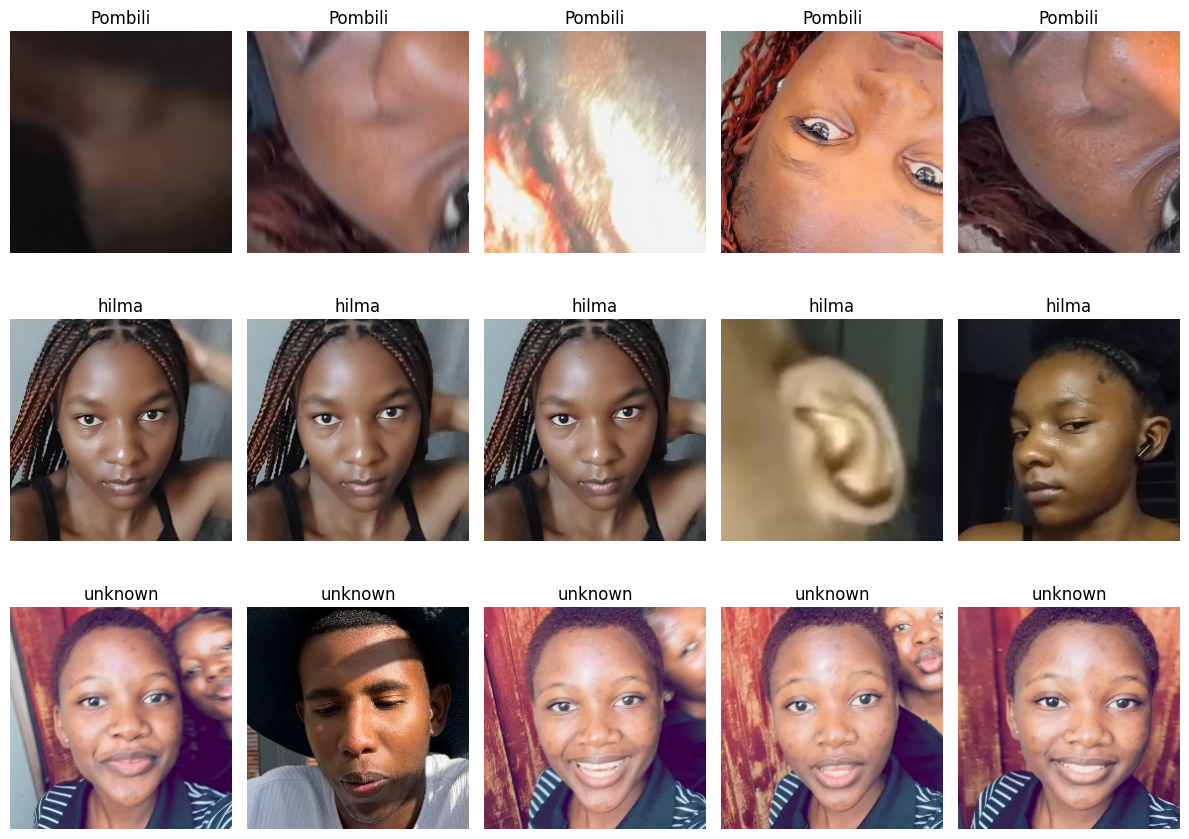

In [5]:
import matplotlib.pyplot as plt, glob, random, os
DATASET = '/content/drive/MyDrive/classification_project/dataset_faces'
classes = sorted(os.listdir(DATASET))
plt.figure(figsize=(12, 3 * len(classes)))
for r, c in enumerate(classes):
    pics = glob.glob(f'{DATASET}/{c}/*.jpg')
    print(c, ':', len(pics), 'pictures')
    for k, p in enumerate(random.sample(pics, min(5, len(pics)))):
        plt.subplot(len(classes), 5, r * 5 + k + 1)
        plt.imshow(plt.imread(p)); plt.axis('off'); plt.title(c)
plt.tight_layout(); plt.show()

In [6]:
import random, shutil
from google.colab import files
random.seed(42)

OUT = '/content/split_faces'
if os.path.exists(OUT):
    shutil.rmtree(OUT)

for item in sorted(os.listdir(DATASET)):
    pics = sorted(glob.glob(f'{DATASET}/{item}/*.jpg'))
    vids = sorted(set(os.path.basename(p).split('_')[1] for p in pics))
    if len(vids) >= 2:
        test = [p for p in pics if f'_{vids[-1]}_' in os.path.basename(p)]
    else:
        random.shuffle(pics)
        test = pics[:int(len(pics) * 0.15)]
    rest = [p for p in pics if p not in test]
    random.shuffle(rest)
    n_val = int(len(rest) * 0.15)
    groups = {'test': test, 'valid': rest[:n_val], 'train': rest[n_val:]}
    for g, lst in groups.items():
        os.makedirs(f'{OUT}/{g}/{item}', exist_ok=True)
        for p in lst:
            shutil.copy(p, f'{OUT}/{g}/{item}')
    print(item, {g: len(l) for g, l in groups.items()})

shutil.make_archive('/content/faces_dataset', 'zip', OUT)
files.download('/content/faces_dataset.zip')

Pombili {'test': 25, 'valid': 11, 'train': 64}
hilma {'test': 50, 'valid': 7, 'train': 43}
unknown {'test': 50, 'valid': 7, 'train': 43}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
import cv2, glob, shutil, os

TARGET = 100
if os.path.exists(DATASET):
    shutil.rmtree(DATASET)

face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
eye_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_eye.xml')
ROTATIONS = [None, cv2.ROTATE_90_CLOCKWISE, cv2.ROTATE_180,
             cv2.ROTATE_90_COUNTERCLOCKWISE]

def find_face(frame, start):
    for k in range(4):
        r = (start + k) % 4
        img = frame if ROTATIONS[r] is None else cv2.rotate(frame, ROTATIONS[r])
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        H, W = gray.shape
        min_side = int(0.15 * min(H, W))
        faces = face_cascade.detectMultiScale(gray, 1.1, 8, minSize=(min_side, min_side))
        for (x, y, w, h) in sorted(faces, key=lambda f: -f[2] * f[3]):
            roi = gray[y:y + h, x:x + w]
            eyes = eye_cascade.detectMultiScale(roi, 1.1, 5, minSize=(int(0.1 * w), int(0.1 * w)))
            sharp = cv2.Laplacian(roi, cv2.CV_64F).var()
            if len(eyes) >= 1 and sharp > 40:
                m = int(0.25 * w)
                crop = img[max(y - m, 0):y + h + m, max(x - m, 0):x + w + m]
                return cv2.resize(crop, (224, 224)), r
    return None, start

for person in sorted(os.listdir(VIDEOS)):
    files = []
    for ext in ('*.mp4', '*.mov', '*.MP4', '*.MOV', '*.3gp'):
        files += glob.glob(f'{VIDEOS}/{person}/{ext}')
    files = sorted(files)
    if not files:
        print(person, ': no videos found')
        continue

    os.makedirs(f'{DATASET}/{person}', exist_ok=True)
    per_video = TARGET // len(files)
    saved = 0
    for v, path in enumerate(files):
        cap = cv2.VideoCapture(path)
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        step = max(total // (per_video * 3), 1)
        idx, n, rot = 0, 0, 0
        while n < per_video:
            ok, frame = cap.read()
            if not ok:
                break
            if idx % step == 0:
                face, rot = find_face(frame, rot)
                if face is not None:
                    cv2.imwrite(f'{DATASET}/{person}/{person}_v{v}_{n:03d}.jpg', face)
                    n += 1
                    saved += 1
            idx += 1
        cap.release()
        print(f'  {person} video {v}: {n} faces')
    print(person, ': saved', saved, 'face pictures from', len(files), 'videos')

  Pombili video 0: 12 faces
  Pombili video 1: 25 faces
  Pombili video 2: 4 faces
  Pombili video 3: 0 faces
Pombili : saved 41 face pictures from 4 videos
  hilma video 0: 44 faces
  hilma video 1: 50 faces
hilma : saved 94 face pictures from 2 videos
  unknown video 0: 0 faces
  unknown video 1: 50 faces
unknown : saved 50 face pictures from 2 videos


Videos with fewer than 20 faces: [('Pombili', 0, 12), ('Pombili', 2, 4), ('Pombili', 3, 0), ('unknown', 0, 0)]


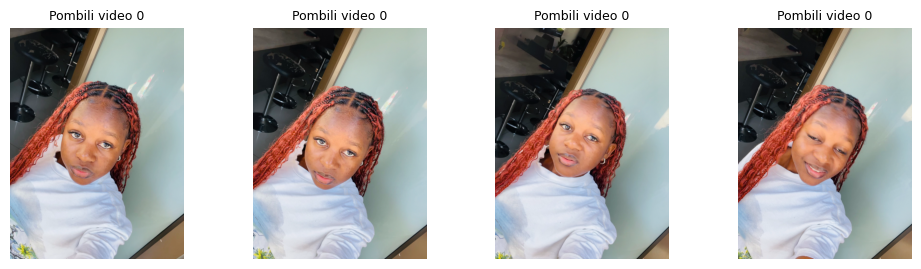

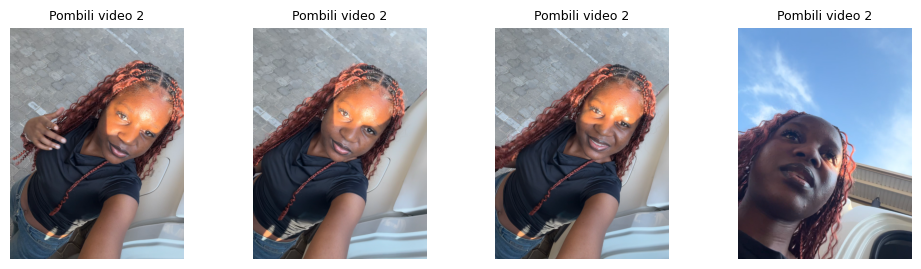

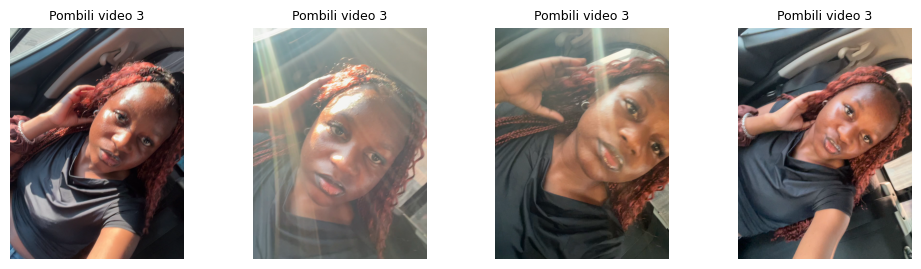

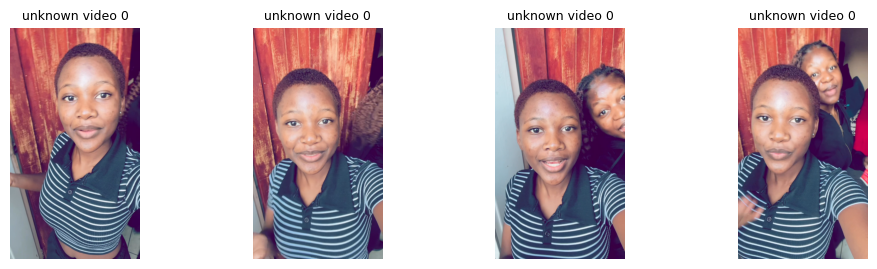

In [8]:
import cv2, glob, matplotlib.pyplot as plt, os

problem = []
for person in sorted(os.listdir(VIDEOS)):
    files = []
    for ext in ('*.mp4', '*.mov', '*.MP4', '*.MOV', '*.3gp'):
        files += glob.glob(f'{VIDEOS}/{person}/{ext}')
    for v, path in enumerate(sorted(files)):
        n = len(glob.glob(f'{DATASET}/{person}/{person}_v{v}_*.jpg'))
        if n < 20:
            problem.append((person, v, path, n))
print('Videos with fewer than 20 faces:', [(p, v, n) for p, v, _, n in problem])

for person, v, path, n in problem:
    cap = cv2.VideoCapture(path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    plt.figure(figsize=(12, 3))
    for k in range(4):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(total * (k + 0.5) / 4))
        ok, frame = cap.read()
        if ok:
            plt.subplot(1, 4, k + 1)
            plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)); plt.axis('off')
            plt.title(f'{person} video {v}', fontsize=9)
    plt.show()
    cap.release()

In [9]:
from google.colab import drive
drive.mount('/content/drive')
import os, glob, shutil, cv2

ROOT = '/content/drive/MyDrive'

def find_folder(root, target, max_depth=4):
    for dirpath, dirnames, _ in os.walk(root):
        if dirpath[len(root):].count(os.sep) >= max_depth:
            dirnames[:] = []
        for d in dirnames:
            if d.lower().replace(' ', '_') == target:
                return os.path.join(dirpath, d)
    return None

VIDEOS = find_folder(ROOT, 'videos_faces')
PHOTOS = find_folder(ROOT, 'photos_faces')
if VIDEOS is None:
    raise FileNotFoundError('Videos_faces not found. Folders in My Drive: ' + str(sorted(os.listdir(ROOT))))
DATASET = os.path.join(os.path.dirname(VIDEOS), 'dataset_faces')
print('Videos_faces :', VIDEOS)
print('Photos_faces :', PHOTOS)

if os.path.exists(DATASET):
    shutil.rmtree(DATASET)

face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
eye_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_eye.xml')
ROTATIONS = [None, cv2.ROTATE_90_CLOCKWISE, cv2.ROTATE_180, cv2.ROTATE_90_COUNTERCLOCKWISE]

def find_face(frame, start=0):
    for k in range(4):
        r = (start + k) % 4
        img = frame if ROTATIONS[r] is None else cv2.rotate(frame, ROTATIONS[r])
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        H, W = gray.shape
        min_side = int(0.15 * min(H, W))
        faces = face_cascade.detectMultiScale(gray, 1.1, 8, minSize=(min_side, min_side))
        for (x, y, w, h) in sorted(faces, key=lambda f: -f[2] * f[3]):
            roi = gray[y:y + h, x:x + w]
            eyes = eye_cascade.detectMultiScale(roi, 1.1, 5, minSize=(int(0.1 * w), int(0.1 * w)))
            sharp = cv2.Laplacian(roi, cv2.CV_64F).var()
            if len(eyes) >= 1 and sharp > 40:
                m = int(0.25 * w)
                crop = img[max(y - m, 0):y + h + m, max(x - m, 0):x + w + m]
                return cv2.resize(crop, (224, 224)), r
    return None, start

VID_EXT = ('.mp4', '.mov', '.3gp')
IMG_EXT = ('.jpg', '.jpeg', '.png')

classes = set(d for d in os.listdir(VIDEOS) if os.path.isdir(os.path.join(VIDEOS, d)))
if PHOTOS:
    classes |= set(d for d in os.listdir(PHOTOS) if os.path.isdir(os.path.join(PHOTOS, d)))

for person in sorted(classes):
    folders = [os.path.join(VIDEOS, person)] + ([os.path.join(PHOTOS, person)] if PHOTOS else [])
    vids, imgs = [], []
    for f in folders:
        if os.path.isdir(f):
            for name in sorted(os.listdir(f)):
                low = name.lower()
                if low.endswith(VID_EXT):
                    vids.append(os.path.join(f, name))
                elif low.endswith(IMG_EXT):
                    imgs.append(os.path.join(f, name))

    os.makedirs(f'{DATASET}/{person}', exist_ok=True)
    total_saved = 0

    # videos: up to 40 faces from each one
    for v, path in enumerate(vids):
        cap = cv2.VideoCapture(path)
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        step = max(total // 120, 1)
        idx, n, rot = 0, 0, 0
        while n < 40:
            ok, frame = cap.read()
            if not ok:
                break
            if idx % step == 0:
                face, rot = find_face(frame, rot)
                if face is not None:
                    cv2.imwrite(f'{DATASET}/{person}/{person}_v{v}_{n:03d}.jpg', face)
                    n += 1
            idx += 1
        cap.release()
        total_saved += n
        print(f'  {person} video {v}: {n} faces')

    # pictures: first half = group "pa", second half = group "pb" (so one half can be the test)
    half = (len(imgs) + 1) // 2
    counts = {'pa': 0, 'pb': 0}
    for i, path in enumerate(imgs):
        img = cv2.imread(path)
        if img is None:
            continue
        face, _ = find_face(img)
        if face is not None:
            g = 'pa' if i < half else 'pb'
            cv2.imwrite(f'{DATASET}/{person}/{person}_{g}_{counts[g]:03d}.jpg', face)
            counts[g] += 1
    total_saved += sum(counts.values())

    print(f'{person}: {len(vids)} videos, {len(imgs)} pictures -> {total_saved} good face pictures '
          f'({len(imgs) - sum(counts.values())} pictures had no clear face and were skipped)')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Videos_faces : /content/drive/MyDrive/classification_project/Videos_faces
Photos_faces : None
  Pombili video 0: 18 faces
  Pombili video 1: 36 faces
  Pombili video 2: 40 faces
  Pombili video 3: 18 faces
  Pombili video 4: 40 faces
  Pombili video 5: 4 faces
  Pombili video 6: 0 faces
Pombili: 7 videos, 0 pictures -> 156 good face pictures (0 pictures had no clear face and were skipped)
  hilma video 0: 40 faces
  hilma video 1: 40 faces
hilma: 2 videos, 0 pictures -> 80 good face pictures (0 pictures had no clear face and were skipped)
  unknown video 0: 0 faces
  unknown video 1: 40 faces
  unknown video 2: 40 faces
unknown: 3 videos, 0 pictures -> 80 good face pictures (0 pictures had no clear face and were skipped)


In [1]:
import matplotlib.pyplot as plt, random, glob, os
classes = sorted(os.listdir(DATASET))
plt.figure(figsize=(14, 3 * len(classes)))
for r, c in enumerate(classes):
    pics = glob.glob(f'{DATASET}/{c}/*.jpg')
    print(c, ':', len(pics), 'pictures')
    for k, p in enumerate(random.sample(pics, min(6, len(pics)))):
        plt.subplot(len(classes), 6, r * 6 + k + 1)
        plt.imshow(plt.imread(p)); plt.axis('off'); plt.title(c, fontsize=9)
plt.tight_layout(); plt.show()

NameError: name 'DATASET' is not defined

In [2]:
from google.colab import drive
drive.mount('/content/drive')
import os, glob

DATASET = '/content/drive/MyDrive/classification_project/dataset_faces'
print('Folder exists:', os.path.exists(DATASET))
for c in sorted(os.listdir(DATASET)):
    print(c, ':', len(glob.glob(f'{DATASET}/{c}/*.jpg')), 'pictures')

Mounted at /content/drive
Folder exists: True
Pombili : 156 pictures
hilma : 80 pictures
unknown : 80 pictures


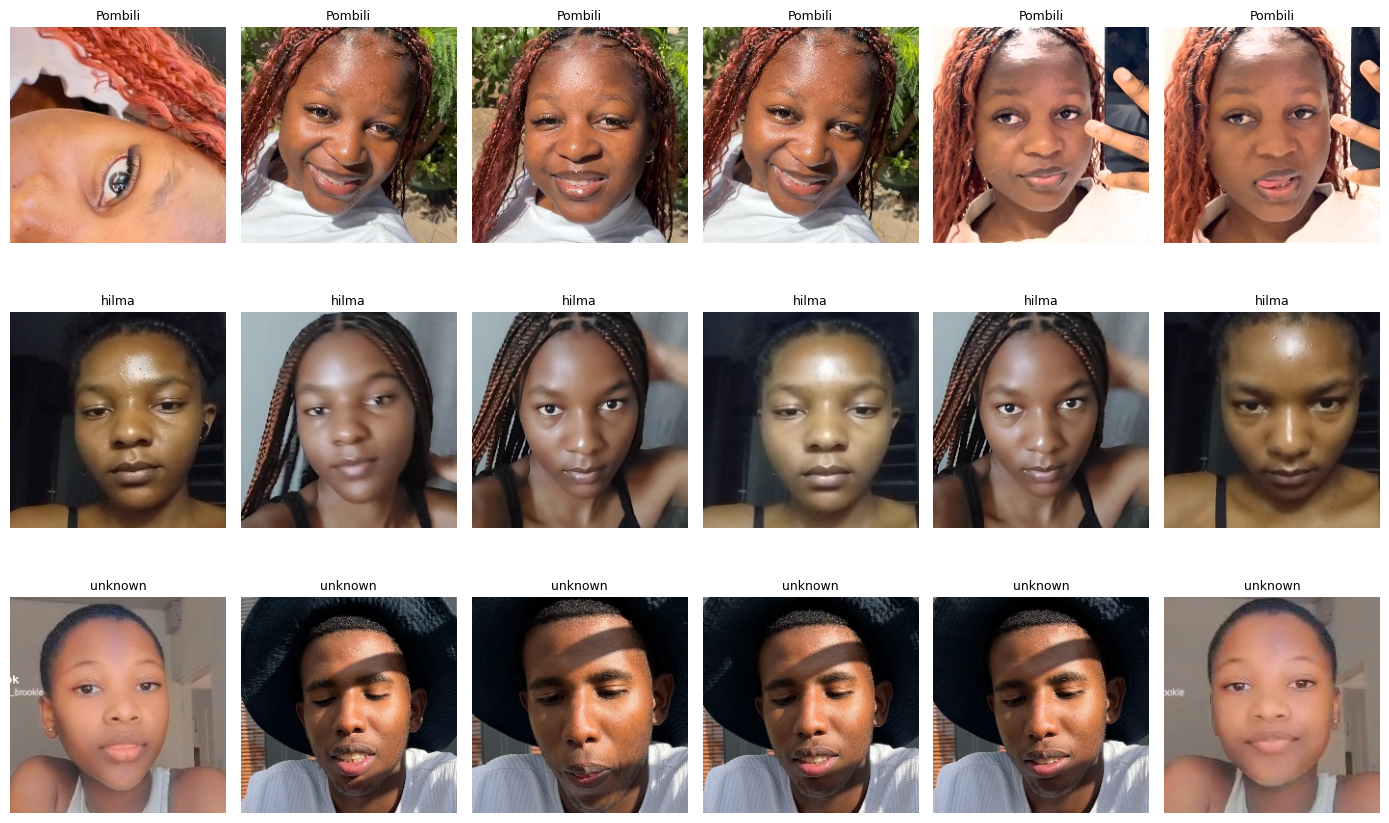

In [3]:
import matplotlib.pyplot as plt, random
classes = sorted(os.listdir(DATASET))
plt.figure(figsize=(14, 3 * len(classes)))
for r, c in enumerate(classes):
    pics = glob.glob(f'{DATASET}/{c}/*.jpg')
    for k, p in enumerate(random.sample(pics, min(6, len(pics)))):
        plt.subplot(len(classes), 6, r * 6 + k + 1)
        plt.imshow(plt.imread(p)); plt.axis('off'); plt.title(c, fontsize=9)
plt.tight_layout(); plt.show()

In [4]:
import random, shutil, collections, glob, os
from google.colab import files
random.seed(42)

MAX_TRAIN = 60
OUT = '/content/split_faces'
if os.path.exists(OUT):
    shutil.rmtree(OUT)

for item in sorted(os.listdir(DATASET)):
    pics = sorted(glob.glob(f'{DATASET}/{item}/*.jpg'))
    by_vid = collections.defaultdict(list)
    for p in pics:
        by_vid[os.path.basename(p).split('_')[1]].append(p)

    usable = [v for v in sorted(by_vid) if len(by_vid[v]) >= 15]
    if len(usable) >= 2:
        test = by_vid[usable[-1]]
        note = f'test = whole video {usable[-1]}'
    else:
        random.shuffle(pics)
        test = pics[:int(len(pics) * 0.15)]
        note = 'WEAK TEST: only one good video, used a random 15%'

    rest = [p for p in pics if p not in test]
    random.shuffle(rest)
    n_val = int(len(rest) * 0.15)
    val, train = rest[:n_val], rest[n_val:][:MAX_TRAIN]
    groups = {'test': test, 'valid': val, 'train': train}
    for g, lst in groups.items():
        os.makedirs(f'{OUT}/{g}/{item}', exist_ok=True)
        for p in lst:
            shutil.copy(p, f'{OUT}/{g}/{item}')
    print(item, {g: len(l) for g, l in groups.items()}, '|', note)

shutil.make_archive('/content/faces_dataset', 'zip', OUT)
files.download('/content/faces_dataset.zip')

Pombili {'test': 40, 'valid': 17, 'train': 60} | test = whole video v4
hilma {'test': 40, 'valid': 6, 'train': 34} | test = whole video v1
unknown {'test': 40, 'valid': 6, 'train': 34} | test = whole video v2


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os, glob, shutil, cv2

ROOT = '/content/drive/MyDrive'

def find_folder(root, target, max_depth=4):
    for dirpath, dirnames, _ in os.walk(root):
        if dirpath[len(root):].count(os.sep) >= max_depth:
            dirnames[:] = []
        for d in dirnames:
            if d.lower().replace(' ', '_') == target:
                return os.path.join(dirpath, d)
    return None

VIDEOS = find_folder(ROOT, 'videos_faces')
if VIDEOS is None:
    raise FileNotFoundError('Videos_faces not found: ' + str(sorted(os.listdir(ROOT))))
DATASET = os.path.join(os.path.dirname(VIDEOS), 'dataset_faces')
if os.path.exists(DATASET):
    shutil.rmtree(DATASET)

face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
eye_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_eye.xml')
ROTATIONS = [None, cv2.ROTATE_90_CLOCKWISE, cv2.ROTATE_180, cv2.ROTATE_90_COUNTERCLOCKWISE]

def find_face(frame, start=0):
    for k in range(4):
        r = (start + k) % 4
        img = frame if ROTATIONS[r] is None else cv2.rotate(frame, ROTATIONS[r])
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        H, W = gray.shape
        min_side = int(0.15 * min(H, W))
        faces = face_cascade.detectMultiScale(gray, 1.1, 8, minSize=(min_side, min_side))
        for (x, y, w, h) in sorted(faces, key=lambda f: -f[2] * f[3]):
            roi = gray[y:y + h, x:x + w]
            eyes = eye_cascade.detectMultiScale(roi, 1.1, 5, minSize=(int(0.1 * w), int(0.1 * w)))
            if len(eyes) >= 1 and cv2.Laplacian(roi, cv2.CV_64F).var() > 40:
                m = int(0.25 * w)
                crop = img[max(y - m, 0):y + h + m, max(x - m, 0):x + w + m]
                return cv2.resize(crop, (224, 224)), r
    return None, start

for person in sorted(d for d in os.listdir(VIDEOS) if os.path.isdir(os.path.join(VIDEOS, d))):
    vids = sorted(f for f in os.listdir(f'{VIDEOS}/{person}')
                  if f.lower().endswith(('.mp4', '.mov', '.3gp')))
    os.makedirs(f'{DATASET}/{person}', exist_ok=True)
    print(person)
    for v, name in enumerate(vids):
        cap = cv2.VideoCapture(f'{VIDEOS}/{person}/{name}')
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        step = max(total // 120, 1)
        idx, n, rot = 0, 0, 0
        while n < 40:
            ok, frame = cap.read()
            if not ok:
                break
            if idx % step == 0:
                face, rot = find_face(frame, rot)
                if face is not None:
                    cv2.imwrite(f'{DATASET}/{person}/{person}_v{v}_{n:03d}.jpg', face)
                    n += 1
            idx += 1
        cap.release()
        print(f'   video v{v}: {n:2d} faces   ({name})')

Mounted at /content/drive
Pombili
   video v0: 18 faces   (IMG_7165.MOV)
   video v1: 36 faces   (IMG_7170.MOV)
   video v2: 40 faces   (IMG_7273.MOV)
   video v3: 18 faces   (IMG_7308.MOV)
   video v4: 40 faces   (IMG_7357.MOV)
   video v5:  4 faces   (IMG_7432.MOV)
   video v6:  0 faces   (IMG_7472.MOV)
hilma
   video v0: 40 faces   (VID-20250428-WA0688.mp4)
   video v1: 40 faces   (WhatsApp Video 2026-10-30 at 21.52.07.mp4)
   video v2: 40 faces   (WhatsApp Video 2026-10-31 at 21.35.56.mp4)
   video v3: 40 faces   (WhatsApp Video 2026-10-31 at 21.36.03.mp4)
   video v4: 40 faces   (WhatsApp Video 2026-10-31 at 21.36.14.mp4)
   video v5: 40 faces   (WhatsApp Video 2026-10-31 at 21.36.15.mp4)
unknown
   video v0:  0 faces   (3F230F59-4CC5-4139-B437-13FBC7DD479C.mov)
   video v1: 40 faces   (IMG_4784.MOV)
   video v2: 40 faces   (VID-20240204-WA0001.mp4)
   video v3: 40 faces   (WhatsApp Video 2026-10-31 at 20.05.08.mp4)
   video v4: 39 faces   (WhatsApp Video 2026-10-31 at 20.09.04.mp

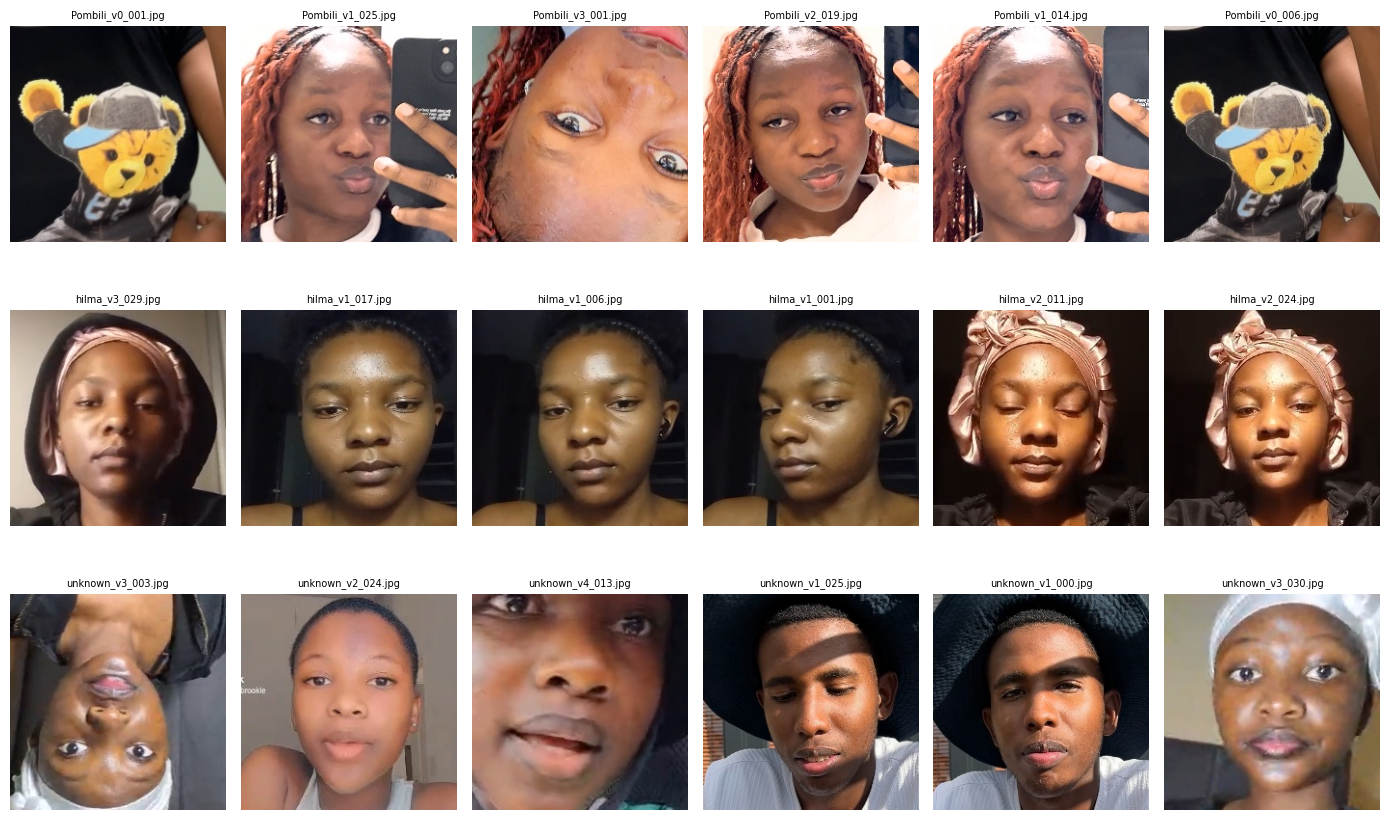

In [2]:
import matplotlib.pyplot as plt, random
classes = sorted(os.listdir(DATASET))
plt.figure(figsize=(14, 3 * len(classes)))
for r, c in enumerate(classes):
    pics = glob.glob(f'{DATASET}/{c}/*.jpg')
    for k, p in enumerate(random.sample(pics, min(6, len(pics)))):
        plt.subplot(len(classes), 6, r * 6 + k + 1)
        plt.imshow(plt.imread(p)); plt.axis('off'); plt.title(os.path.basename(p), fontsize=7)
plt.tight_layout(); plt.show()

In [3]:
import random, collections
from google.colab import files
random.seed(42)

MAX_TRAIN = 80
OUT = '/content/split_faces2'
if os.path.exists(OUT):
    shutil.rmtree(OUT)

all_ok = True
for item in sorted(os.listdir(DATASET)):
    by_vid = collections.defaultdict(list)
    for p in sorted(glob.glob(f'{DATASET}/{item}/*.jpg')):
        by_vid[os.path.basename(p).split('_')[1]].append(p)
    usable = sorted([v for v in by_vid if len(by_vid[v]) >= 15], key=lambda s: int(s[1:]))
    if len(usable) < 3:
        print(f'{item}: only {len(usable)} good videos. Need at least 3, so film more.')
        all_ok = False
        continue

    test_v, val_v = usable[-1], usable[-2]
    train = [p for v in usable[:-2] for p in by_vid[v]]
    random.shuffle(train)
    train = train[:MAX_TRAIN]
    groups = {'test': by_vid[test_v], 'valid': by_vid[val_v], 'train': train}
    for g, lst in groups.items():
        os.makedirs(f'{OUT}/{g}/{item}', exist_ok=True)
        for p in lst:
            shutil.copy(p, f'{OUT}/{g}/{item}')
    print(item, {g: len(l) for g, l in groups.items()}, f'| test={test_v}, valid={val_v}, train={usable[:-2]}')

if all_ok:
    shutil.make_archive('/content/faces_dataset_v2', 'zip', OUT)
    files.download('/content/faces_dataset_v2.zip')

Pombili {'test': 40, 'valid': 18, 'train': 80} | test=v4, valid=v3, train=['v0', 'v1', 'v2']
hilma {'test': 40, 'valid': 40, 'train': 80} | test=v5, valid=v4, train=['v0', 'v1', 'v2', 'v3']
unknown {'test': 39, 'valid': 40, 'train': 80} | test=v4, valid=v3, train=['v1', 'v2']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
from google.colab import drive
drive.mount('/content/drive')
import os, glob, shutil, cv2

ROOT = '/content/drive/MyDrive'

def find_folder(root, target, max_depth=4):
    for dirpath, dirnames, _ in os.walk(root):
        if dirpath[len(root):].count(os.sep) >= max_depth:
            dirnames[:] = []
        for d in dirnames:
            if d.lower().replace(' ', '_') == target:
                return os.path.join(dirpath, d)
    return None

VIDEOS = find_folder(ROOT, 'videos_faces')
if VIDEOS is None:
    raise FileNotFoundError('Videos_faces not found: ' + str(sorted(os.listdir(ROOT))))
DATASET = os.path.join(os.path.dirname(VIDEOS), 'dataset_faces')
if os.path.exists(DATASET):
    shutil.rmtree(DATASET)

face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
eye_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_eye.xml')
ROTATIONS = [None, cv2.ROTATE_90_CLOCKWISE, cv2.ROTATE_180, cv2.ROTATE_90_COUNTERCLOCKWISE]

def find_face(frame):
    # try all 4 rotations, keep the most face-like result with eyes in the UPPER half
    best = None
    for rot in ROTATIONS:
        img = frame if rot is None else cv2.rotate(frame, rot)
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        H, W = gray.shape
        min_side = int(0.15 * min(H, W))
        res = face_cascade.detectMultiScale3(gray, 1.1, 8, minSize=(min_side, min_side),
                                             outputRejectLevels=True)
        if len(res) != 3 or len(res[0]) == 0:
            continue
        for (x, y, w, h), wt in zip(res[0], res[2]):
            roi = gray[y:y + h, x:x + w]
            eyes = eye_cascade.detectMultiScale(roi, 1.1, 5, minSize=(int(0.1 * w), int(0.1 * w)))
            upper = [e for e in eyes if (e[1] + e[3] / 2) < 0.6 * h]
            if upper and cv2.Laplacian(roi, cv2.CV_64F).var() > 40:
                if best is None or wt > best[0]:
                    best = (wt, img, x, y, w, h)
    if best is None:
        return None
    _, img, x, y, w, h = best
    m = int(0.25 * w)
    return cv2.resize(img[max(y - m, 0):y + h + m, max(x - m, 0):x + w + m], (224, 224))

for person in sorted(d for d in os.listdir(VIDEOS) if os.path.isdir(os.path.join(VIDEOS, d))):
    vids = sorted(f for f in os.listdir(f'{VIDEOS}/{person}')
                  if f.lower().endswith(('.mp4', '.mov', '.3gp')))
    os.makedirs(f'{DATASET}/{person}', exist_ok=True)
    print(person)
    for v, name in enumerate(vids):
        cap = cv2.VideoCapture(f'{VIDEOS}/{person}/{name}')
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        step = max(total // 120, 1)
        idx, n = 0, 0
        while n < 40:
            ok, frame = cap.read()
            if not ok:
                break
            if idx % step == 0:
                h0, w0 = frame.shape[:2]
                s = 800 / max(h0, w0)
                if s < 1:
                    frame = cv2.resize(frame, (int(w0 * s), int(h0 * s)))
                face = find_face(frame)
                if face is not None:
                    cv2.imwrite(f'{DATASET}/{person}/{person}_v{v}_{n:03d}.jpg', face)
                    n += 1
            idx += 1
        cap.release()
        print(f'   video v{v}: {n:2d} faces   ({name})')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Pombili
   video v0:  4 faces   (IMG_7165.MOV)
   video v1: 40 faces   (IMG_7170.MOV)
   video v2: 40 faces   (IMG_7273.MOV)
   video v3: 21 faces   (IMG_7308.MOV)
   video v4: 40 faces   (IMG_7357.MOV)
   video v5:  2 faces   (IMG_7432.MOV)
   video v6:  6 faces   (IMG_7472.MOV)
hilma
   video v0: 40 faces   (VID-20250428-WA0688.mp4)
   video v1: 40 faces   (WhatsApp Video 2026-10-30 at 21.52.07.mp4)
   video v2: 40 faces   (WhatsApp Video 2026-10-31 at 21.35.56.mp4)
   video v3: 40 faces   (WhatsApp Video 2026-10-31 at 21.36.03.mp4)
   video v4: 40 faces   (WhatsApp Video 2026-10-31 at 21.36.14.mp4)
   video v5: 40 faces   (WhatsApp Video 2026-10-31 at 21.36.15.mp4)
unknown
   video v0: 40 faces   (3F230F59-4CC5-4139-B437-13FBC7DD479C.mov)
   video v1: 40 faces   (IMG_4784.MOV)
   video v2: 40 faces   (VID-20240204-WA0001.mp4)
   video v3: 40 faces   (Whats

In [5]:
from google.colab import drive
drive.mount('/content/drive')
import os, glob, shutil, cv2

ROOT = '/content/drive/MyDrive'

def find_folder(root, target, max_depth=4):
    for dirpath, dirnames, _ in os.walk(root):
        if dirpath[len(root):].count(os.sep) >= max_depth:
            dirnames[:] = []
        for d in dirnames:
            if d.lower().replace(' ', '_') == target:
                return os.path.join(dirpath, d)
    return None

VIDEOS = find_folder(ROOT, 'videos_faces')
if VIDEOS is None:
    raise FileNotFoundError('Videos_faces not found: ' + str(sorted(os.listdir(ROOT))))
DATASET = os.path.join(os.path.dirname(VIDEOS), 'dataset_faces')
if os.path.exists(DATASET):
    shutil.rmtree(DATASET)

face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
eye_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_eye.xml')
ROTATIONS = [None, cv2.ROTATE_90_CLOCKWISE, cv2.ROTATE_180, cv2.ROTATE_90_COUNTERCLOCKWISE]

def find_face(frame):
    # try all 4 rotations, keep the most face-like result with eyes in the UPPER half
    best = None
    for rot in ROTATIONS:
        img = frame if rot is None else cv2.rotate(frame, rot)
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        H, W = gray.shape
        min_side = int(0.15 * min(H, W))
        res = face_cascade.detectMultiScale3(gray, 1.1, 8, minSize=(min_side, min_side),
                                             outputRejectLevels=True)
        if len(res) != 3 or len(res[0]) == 0:
            continue
        for (x, y, w, h), wt in zip(res[0], res[2]):
            roi = gray[y:y + h, x:x + w]
            eyes = eye_cascade.detectMultiScale(roi, 1.1, 5, minSize=(int(0.1 * w), int(0.1 * w)))
            upper = [e for e in eyes if (e[1] + e[3] / 2) < 0.6 * h]
            if upper and cv2.Laplacian(roi, cv2.CV_64F).var() > 40:
                if best is None or wt > best[0]:
                    best = (wt, img, x, y, w, h)
    if best is None:
        return None
    _, img, x, y, w, h = best
    m = int(0.25 * w)
    return cv2.resize(img[max(y - m, 0):y + h + m, max(x - m, 0):x + w + m], (224, 224))

for person in sorted(d for d in os.listdir(VIDEOS) if os.path.isdir(os.path.join(VIDEOS, d))):
    vids = sorted(f for f in os.listdir(f'{VIDEOS}/{person}')
                  if f.lower().endswith(('.mp4', '.mov', '.3gp')))
    os.makedirs(f'{DATASET}/{person}', exist_ok=True)
    print(person)
    for v, name in enumerate(vids):
        cap = cv2.VideoCapture(f'{VIDEOS}/{person}/{name}')
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        step = max(total // 120, 1)
        idx, n = 0, 0
        while n < 40:
            ok, frame = cap.read()
            if not ok:
                break
            if idx % step == 0:
                h0, w0 = frame.shape[:2]
                s = 800 / max(h0, w0)
                if s < 1:
                    frame = cv2.resize(frame, (int(w0 * s), int(h0 * s)))
                face = find_face(frame)
                if face is not None:
                    cv2.imwrite(f'{DATASET}/{person}/{person}_v{v}_{n:03d}.jpg', face)
                    n += 1
            idx += 1
        cap.release()
        print(f'   video v{v}: {n:2d} faces   ({name})')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Pombili
   video v0:  4 faces   (IMG_7165.MOV)
   video v1: 40 faces   (IMG_7170.MOV)
   video v2: 40 faces   (IMG_7273.MOV)
   video v3: 21 faces   (IMG_7308.MOV)
   video v4: 40 faces   (IMG_7357.MOV)
   video v5:  2 faces   (IMG_7432.MOV)
   video v6:  6 faces   (IMG_7472.MOV)
hilma
   video v0: 40 faces   (VID-20250428-WA0688.mp4)
   video v1: 40 faces   (WhatsApp Video 2026-10-30 at 21.52.07.mp4)
   video v2: 40 faces   (WhatsApp Video 2026-10-31 at 21.35.56.mp4)
   video v3: 40 faces   (WhatsApp Video 2026-10-31 at 21.36.03.mp4)
   video v4: 40 faces   (WhatsApp Video 2026-10-31 at 21.36.14.mp4)
   video v5: 40 faces   (WhatsApp Video 2026-10-31 at 21.36.15.mp4)
unknown
   video v0: 40 faces   (3F230F59-4CC5-4139-B437-13FBC7DD479C.mov)
   video v1: 40 faces   (IMG_4784.MOV)
   video v2: 40 faces   (VID-20240204-WA0001.mp4)
   video v3: 40 faces   (Whats

Pombili : 153 pictures
hilma : 240 pictures
unknown : 198 pictures


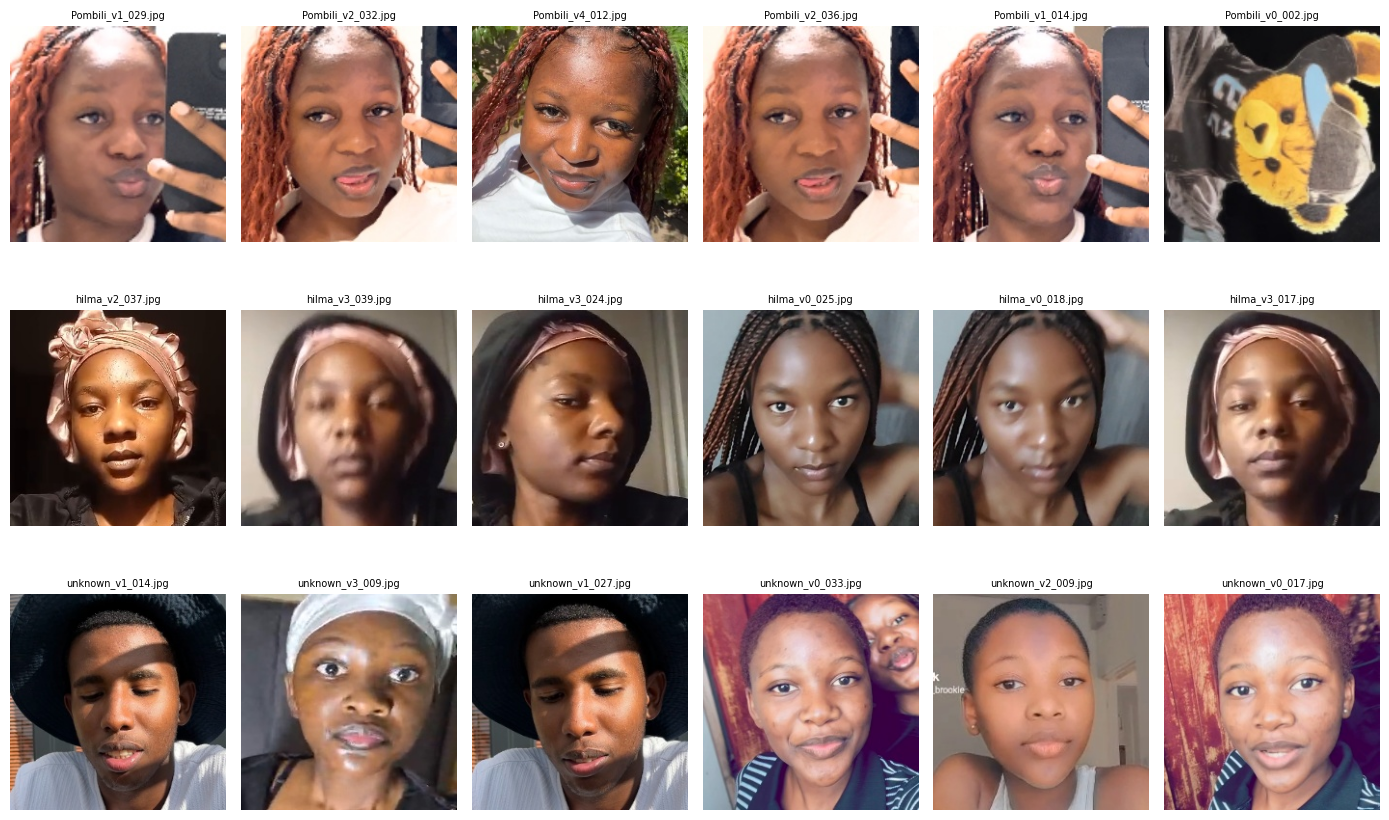

In [6]:
import matplotlib.pyplot as plt, random
classes = sorted(os.listdir(DATASET))
plt.figure(figsize=(14, 3 * len(classes)))
for r, c in enumerate(classes):
    pics = glob.glob(f'{DATASET}/{c}/*.jpg')
    print(c, ':', len(pics), 'pictures')
    for k, p in enumerate(random.sample(pics, min(6, len(pics)))):
        plt.subplot(len(classes), 6, r * 6 + k + 1)
        plt.imshow(plt.imread(p)); plt.axis('off'); plt.title(os.path.basename(p), fontsize=7)
plt.tight_layout(); plt.show()

In [2]:
from google.colab import drive
drive.mount('/content/drive')
import os, re, cv2

ROOT = '/content/drive/MyDrive'

def find_folder(root, target, max_depth=4):
    for dirpath, dirnames, _ in os.walk(root):
        if dirpath[len(root):].count(os.sep) >= max_depth:
            dirnames[:] = []
        for d in dirnames:
            if d.lower().replace(' ', '_') == target:
                return os.path.join(dirpath, d)
    return None

NEW = find_folder(ROOT, 'videos_new')
DATASET = find_folder(ROOT, 'dataset_faces')
if NEW is None or DATASET is None:
    print('Videos_new found :', NEW)
    print('dataset_faces found:', DATASET)
    print('Folders in My Drive:', sorted(os.listdir(ROOT)))
    raise SystemExit('Create/upload the missing folder, then run again.')

print('Videos_new   :', NEW)
print('dataset_faces:', DATASET, '->', sorted(os.listdir(DATASET)))

face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
eye_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_eye.xml')
ROTATIONS = [None, cv2.ROTATE_90_CLOCKWISE, cv2.ROTATE_180, cv2.ROTATE_90_COUNTERCLOCKWISE]

def find_face(frame):
    best = None
    for rot in ROTATIONS:
        img = frame if rot is None else cv2.rotate(frame, rot)
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        H, W = gray.shape
        min_side = int(0.15 * min(H, W))
        res = face_cascade.detectMultiScale3(gray, 1.1, 8, minSize=(min_side, min_side),
                                             outputRejectLevels=True)
        if len(res) != 3 or len(res[0]) == 0:
            continue
        for (x, y, w, h), wt in zip(res[0], res[2]):
            roi = gray[y:y + h, x:x + w]
            eyes = eye_cascade.detectMultiScale(roi, 1.1, 5, minSize=(int(0.1 * w), int(0.1 * w)))
            upper = [e for e in eyes if (e[1] + e[3] / 2) < 0.6 * h]
            if upper and cv2.Laplacian(roi, cv2.CV_64F).var() > 40:
                if best is None or wt > best[0]:
                    best = (wt, img, x, y, w, h)
    if best is None:
        return None
    _, img, x, y, w, h = best
    m = int(0.25 * w)
    return cv2.resize(img[max(y - m, 0):y + h + m, max(x - m, 0):x + w + m], (224, 224))

people = [d for d in sorted(os.listdir(NEW)) if os.path.isdir(os.path.join(NEW, d))]
for person in people:
    os.makedirs(f'{DATASET}/{person}', exist_ok=True)
    used = []
    for f in os.listdir(f'{DATASET}/{person}'):
        m = re.search(r'_v(\d+)_', f)
        if m:
            used.append(int(m.group(1)))
    start = max(used) + 1 if used else 0
    vids = sorted(f for f in os.listdir(f'{NEW}/{person}')
                  if f.lower().endswith(('.mp4', '.mov', '.avi', '.wmv', '.3gp')))
    print(person, '| new videos start at v%d' % start, '|', len(vids), 'videos found')
    for k, name in enumerate(vids):
        v = start + k
        cap = cv2.VideoCapture(f'{NEW}/{person}/{name}')
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        step = max(total // 120, 1)
        idx, n = 0, 0
        while n < 40:
            ok, frame = cap.read()
            if not ok:
                break
            if idx % step == 0:
                h0, w0 = frame.shape[:2]
                s = 800 / max(h0, w0)
                if s < 1:
                    frame = cv2.resize(frame, (int(w0 * s), int(h0 * s)))
                face = find_face(frame)
                if face is not None:
                    cv2.imwrite(f'{DATASET}/{person}/{person}_v{v}_{n:03d}.jpg', face)
                    n += 1
            idx += 1
        cap.release()
        print(f'   video v{v}: {n:2d} faces   ({name})')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Videos_new   : /content/drive/MyDrive/classification_project/Videos_new
dataset_faces: /content/drive/MyDrive/classification_project/dataset_faces -> ['Pombili', 'hilma', 'unknown']
hilma | new videos start at v6 | 5 videos found
   video v6: 40 faces   (zz_me1.mp4.mp4)
   video v7: 40 faces   (zz_me2.mp4.mp4)
   video v8: 40 faces   (zz_me3.mp4.mp4)
   video v9: 40 faces   (zz_me4.mp4.mp4)
   video v10: 40 faces   (zz_me5.mp4.mp4)


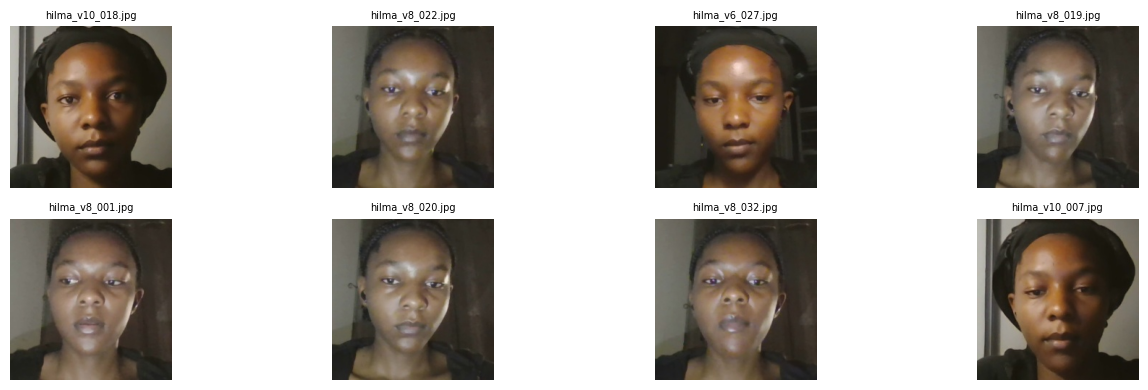

In [3]:
import glob, random, matplotlib.pyplot as plt
D = '/content/drive/MyDrive/classification_project/dataset_faces'
pics = [p for v in range(6, 11) for p in glob.glob(f'{D}/hilma/hilma_v{v}_*.jpg')]
plt.figure(figsize=(14, 4))
for k, p in enumerate(random.sample(pics, 8)):
    plt.subplot(2, 4, k + 1); plt.imshow(plt.imread(p)); plt.axis('off'); plt.title(p.split('/')[-1], fontsize=7)
plt.tight_layout(); plt.show()

In [4]:
import os, glob, random, shutil, collections
from google.colab import files
random.seed(42)

DATASET = '/content/drive/MyDrive/classification_project/dataset_faces'
MAX_TRAIN = 150
OUT = '/content/split_faces3'
if os.path.exists(OUT):
    shutil.rmtree(OUT)

all_ok = True
for item in sorted(os.listdir(DATASET)):
    by_vid = collections.defaultdict(list)
    for p in sorted(glob.glob(f'{DATASET}/{item}/*.jpg')):
        by_vid[os.path.basename(p).split('_')[1]].append(p)
    usable = sorted([v for v in by_vid if len(by_vid[v]) >= 15], key=lambda s: int(s[1:]))
    if len(usable) < 3:
        print(f'{item}: only {len(usable)} good videos. Need at least 3.')
        all_ok = False
        continue
    test_v, val_v = usable[-1], usable[-2]
    train = [p for v in usable[:-2] for p in by_vid[v]]
    random.shuffle(train)
    train = train[:MAX_TRAIN]
    groups = {'test': by_vid[test_v], 'valid': by_vid[val_v], 'train': train}
    for g, lst in groups.items():
        os.makedirs(f'{OUT}/{g}/{item}', exist_ok=True)
        for p in lst:
            shutil.copy(p, f'{OUT}/{g}/{item}')
    print(item, {g: len(l) for g, l in groups.items()}, f'| test={test_v}, valid={val_v}')

if all_ok:
    shutil.make_archive('/content/faces_dataset_v3', 'zip', OUT)
    files.download('/content/faces_dataset_v3.zip')

Pombili {'test': 40, 'valid': 21, 'train': 80} | test=v4, valid=v3
hilma {'test': 40, 'valid': 40, 'train': 150} | test=v10, valid=v9
unknown {'test': 38, 'valid': 40, 'train': 120} | test=v4, valid=v3


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>